# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 7b: IndoBERT - Skema 2 "Tokenizer" (fine-tuning penuh)
Tokenizer subword IndoBERT + bobot pre-trained `indobenchmark/indobert-base-p1` -> kepala klasifikasi baru (6 kelas) -> fine-tuning penuh (semua layer dilatih)

Cara kerja normal IndoBERT: tidak ada yang dibekukan (frozen)

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`
- Output: `outputs/indobert_tokenizer_val_results.json`, `outputs/models/indobert_tokenizer.pt`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [1]:
import os, json, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/indobert_tokenizer_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Tokenizer dan bobot pre-trained milik IndoBERT sendiri (BERT, WordPiece)
MODEL_NAME = "indobenchmark/indobert-base-p1"
MAX_LEN = 128 # dalam token subword (termasuk token khusus)

# Hyperparameter tetap, standar fine-tuning Transformer (tanpa tuning)
BATCH_SIZE  = 32
EPOCHS = 15
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
CLIP_NORM = 1.0


for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
NUM_CLASSES = len(labels)
assert all(label_map[l] == i for i, l in enumerate(labels))
y_train_list = [label_map[l] for l in train_df[LABEL_COL]]
y_val_list = [label_map[l] for l in val_df[LABEL_COL]]
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenizer subword asli IndoBERT

Skema 2 "Tokenizer":  
Pada skema ini, IndoBERT menggunakan tokenizer subword asli miliknya sendiri (checkpoint: indobenchmark/indobert-base-p1)

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None: # jika checkpoint tidak mendefinisikan pad token
    tokenizer.pad_token = "[PAD]"
print(f"Checkpoint: {MODEL_NAME} | vocab subword: {len(tokenizer)} | pad id: {tokenizer.pad_token_id}")

contoh = train_df[TEXT_COL].iloc[0]
print("Contoh teks:", contoh[:80])
print("Subword:", tokenizer.tokenize(contoh)[:12])

# Token khusus ([CLS]/[SEP] atau <s>/</s>) ditambahkan otomatis oleh tokenizer
# Padding dilakukan per batch (dinamis)
train_ids = tokenizer(train_df[TEXT_COL].tolist(), truncation=True, max_length=MAX_LEN)["input_ids"]
val_ids = tokenizer(val_df[TEXT_COL].tolist(), truncation=True, max_length=MAX_LEN)["input_ids"]

full_len = np.array([len(x) for x in tokenizer(train_df[TEXT_COL].tolist(), truncation=False)["input_ids"]])
trunc_pct = (full_len > MAX_LEN).mean() * 100
VOCAB_SIZE = len(tokenizer)
print(f"Panjang subword train (dengan token khusus): rata-rata {full_len.mean():.1f} | persentil 95 = {np.percentile(full_len, 95):.0f} | maks = {full_len.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {trunc_pct:.2f}%")
PAD_FOR_COLLATE = tokenizer.pad_token_id

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Checkpoint: indobenchmark/indobert-base-p1 | vocab subword: 30521 | pad id: 0
Contoh teks: 365. kalau mau gestun limit kamu di spaylater, gopay coin, gopaylater, akulaku, 
Subword: ['365', '.', 'kalau', 'mau', 'ges', '##tu', '##n', 'limit', 'kamu', 'di', 'spa', '##yl']
Panjang subword train (dengan token khusus): rata-rata 24.5 | persentil 95 = 61 | maks = 88
Teks train yang terpotong oleh MAX_LEN=128: 0.00%


In [3]:
def make_collate(pad_id):
    def collate(batch): # batch: list of (ids, label); pad ke panjang terpanjang di batch
        L = max(len(ids) for ids, _ in batch)
        input_ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        attn = torch.zeros((len(batch), L), dtype=torch.long)
        for i, (ids, _) in enumerate(batch):
            input_ids[i, :len(ids)] = torch.tensor(ids)
            attn[i, :len(ids)] = 1
        return {"input_ids": input_ids, "attention_mask": attn,
                "labels": torch.tensor([y for _, y in batch], dtype=torch.long)}
    return collate

collate_fn = make_collate(PAD_FOR_COLLATE)
train_loader = DataLoader(list(zip(train_ids, y_train_list)), batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(list(zip(val_ids, y_val_list)), batch_size=64, shuffle=False, collate_fn=collate_fn)
b0 = next(iter(val_loader))
print("Contoh batch -> input_ids:", tuple(b0["input_ids"].shape), "| attention_mask:", tuple(b0["attention_mask"].shape))

Contoh batch -> input_ids: (64, 63) | attention_mask: (64, 63)


### Step 3 - Muat IndoBERT pre-trained (fine-tuning penuh)

In [4]:
# num_labels=6 -> kepala klasifikasi baru (acak)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES,
    id2label={i: l for i, l in enumerate(labels)}, label2id=label_map).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# Fine-tuning penuh, tidak ada yang dibekukan (frozen)
assert all(p.requires_grad for p in model.parameters())
print(f"Arsitektur: {model.config.model_type} | layer: {model.config.num_hidden_layers} | hidden: {model.config.hidden_size}")
print(f"Total parameter dilatih: {n_params/1e6:.1f} juta (semua requires_grad = True, fine-tuning penuh)")

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Arsitektur: bert | layer: 12 | hidden: 768
Total parameter dilatih: 124.4 juta (semua requires_grad = True, fine-tuning penuh)


### Step 4 - Training (satu run, 15 epoch, model epoch terakhir yang dievaluasi)
Loss `CrossEntropyLoss` (tanpa class weight)  
Optimizer AdamW  
Warmup 10% lalu penurunan linear, gradient clipping 1.0, mixed precision di GPU  
Tidak memilih epoch terbaik di validation  
Akan ditunjukkan lewat grafik jika seandainya terjadi overfitting

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
use_amp = device.type == "cuda" # mixed precision (fp16) di GPU: lebih cepat & hemat memori
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            ids = batch["input_ids"].to(device); am = batch["attention_mask"].to(device); yb = batch["labels"].to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=ids, attention_mask=am).logits
            loss = criterion(logits.float(), yb)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
                scaler.step(optimizer); scaler.update(); scheduler.step()
            tot_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time()-t0:.0f} dtk")
print(f"Selesai dalam {time.time()-t0:.0f} detik")

torch.save(model.state_dict(), f"{MODEL_DIR}/indobert_tokenizer.pt") # ukuran file bisa ratusan MB

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch  1/15 | train loss 1.3932 acc 0.4595 | val loss 0.7414 acc 0.7460 | 23 dtk
Epoch  2/15 | train loss 0.6771 acc 0.7677 | val loss 0.6611 acc 0.7583 | 46 dtk
Epoch  3/15 | train loss 0.4446 acc 0.8519 | val loss 0.6900 acc 0.7725 | 68 dtk
Epoch  4/15 | train loss 0.2670 acc 0.9144 | val loss 0.8155 acc 0.7687 | 90 dtk
Epoch  5/15 | train loss 0.1422 acc 0.9577 | val loss 0.9267 acc 0.7716 | 112 dtk
Epoch  6/15 | train loss 0.0738 acc 0.9789 | val loss 1.0310 acc 0.7649 | 134 dtk
Epoch  7/15 | train loss 0.0423 acc 0.9888 | val loss 1.1845 acc 0.7687 | 157 dtk
Epoch  8/15 | train loss 0.0206 acc 0.9947 | val loss 1.2599 acc 0.7744 | 179 dtk
Epoch  9/15 | train loss 0.0156 acc 0.9957 | val loss 1.2508 acc 0.7877 | 201 dtk
Epoch 10/15 | train loss 0.0070 acc 0.9986 | val loss 1.3154 acc 0.7810 | 224 dtk
Epoch 11/15 | train loss 0.0032 acc 0.9992 | val loss 1.3353 acc 0.7877 | 246 dtk
Epoch 12/15 | train loss 0.0014 acc 1.0000 | val loss 1.4067 acc 0.7773 | 268 dtk
Epoch 13/15 | train 

### Step 5 - Kurva training vs validation (loss & accuracy)

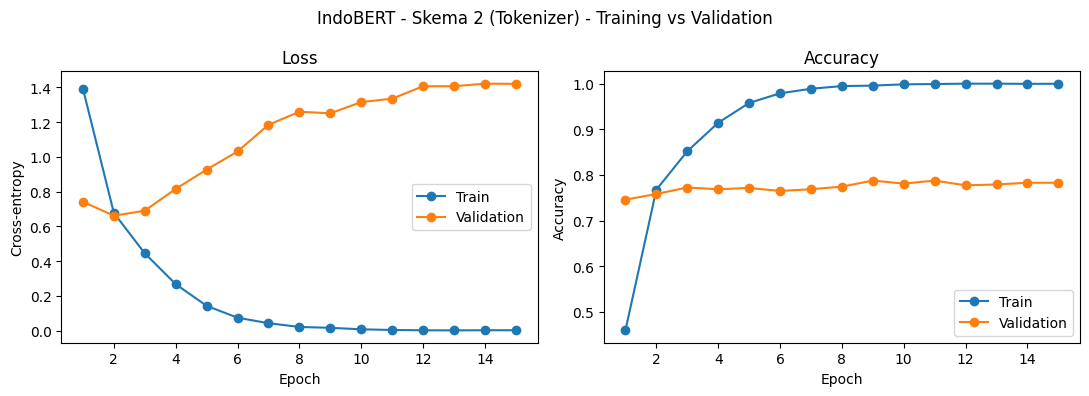

Val loss terendah di epoch 2 (0.6611); epoch terakhir: 1.4205


In [6]:
ep_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep_axis, history["train_loss"], "o-", label="Train")
axes[0].plot(ep_axis, history["val_loss"], "o-", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(ep_axis, history["train_acc"], "o-", label="Train")
axes[1].plot(ep_axis, history["val_acc"], "o-", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("IndoBERT - Skema 2 (Tokenizer) - Training vs Validation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07b_indobert_tokenizer_curves.png", dpi=150)
plt.show()

best_ep = int(np.argmin(history["val_loss"])) + 1
print(f"Val loss terendah di epoch {best_ep} ({min(history['val_loss']):.4f}); epoch terakhir: {history['val_loss'][-1]:.4f}")

### Step 6 - Evaluasi di validation set (model epoch terakhir)

In [7]:
model.eval()
preds = []
with torch.no_grad():
    for batch in val_loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
        preds.append(logits.argmax(1).cpu())
pred_idx = torch.cat(preds).numpy()

y_val_str = val_df[LABEL_COL].values
y_pred_str = np.array([labels[i] for i in pred_idx])

acc = accuracy_score(y_val_str, y_pred_str)
macro_p = precision_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_r = recall_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_f1 = f1_score(y_val_str, y_pred_str, average="macro")

kelas_terbanyak = train_df[LABEL_COL].value_counts().idxmax()
acc_mayoritas = (val_df[LABEL_COL] == kelas_terbanyak).mean()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {acc_mayoritas:.4f}")
print(f"IndoBERT - Skema 2 (Tokenizer) (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")
print("Jumlah kelas yang pernah diprediksi:", len(set(y_pred_str)), "dari", NUM_CLASSES)

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val_str, y_pred_str, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val_str)]
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
IndoBERT - Skema 2 (Tokenizer) (val): accuracy = 0.7829 | macro-F1 = 0.7922
Jumlah kelas yang pernah diprediksi: 6 dari 6


,precision,recall,f1-score,support
anger,0.8075,0.7738,0.7903,168
fear,0.8837,0.8382,0.8604,136
joy,0.7663,0.746,0.7560,189
love,0.7111,0.8496,0.7742,113
neutral,0.7535,0.7181,0.7354,298
sad,0.8086,0.8675,0.8371,151
accuracy,,,0.7829,1055
macro avg,0.7885,0.7989,0.7922,1055
weighted avg,0.7845,0.7829,0.7826,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,130,4,6,6,17,5
asli_fear,4,114,5,2,8,3
asli_joy,3,1,141,15,24,5
asli_love,3,0,2,96,10,2
asli_neutral,20,8,27,13,214,16
asli_sad,1,2,3,3,11,131


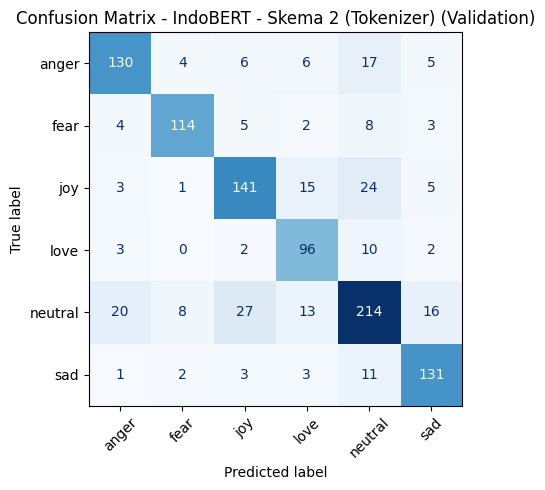

In [8]:
cm = confusion_matrix(y_val_str, y_pred_str, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - IndoBERT - Skema 2 (Tokenizer) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07b_indobert_tokenizer_confusion_matrix_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [9]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "IndoBERT", "feature_extraction": "tokenizer", "split": "validation",
               "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
               "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
               "extractor": "tokenizer + bobot pretrained indobenchmark/indobert-base-p1, fine-tuning penuh",
               "vocab_size": int(VOCAB_SIZE), "max_len": int(MAX_LEN), "epochs": EPOCHS, "lr": LR,
               "batch_size": BATCH_SIZE, "n_trainable_params": int(n_params), "evaluated_epoch": "last"}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/indobert_tokenizer_val_results.json


### Notes Part 7b:
- Vocabulary | MAX_LEN | parameter dilatih: 30521 | 128 | 124.4 juta
- Teks train terpotong oleh MAX_LEN: 0.00%
- Train acc | Val acc (epoch terakhir): 0.9998 | 0.7829
- Val loss terendah di epoch: epoch ke-2 (epoch terakhir: 15)
- Accuracy | Macro-F1 (validation): 0.7829 | 0.7922 (acuan tebak-mayoritas: 0.2825)
- Macro-Precision | Macro-Recall: 0.7885 | 0.7989
- F1 tertinggi | terendah per kelas: fear (0.8604) | neutral (0.7354)
- Pasangan kelas yang paling sering tertukar: joy dan neutral (51 kesalahan di dua arah)
- Test set belum disentuh.